# Question 4 – Extract the data from the e-mails and display it as HTML

**Task.** Read the e-mails in the folder `מיילים/`, extract their data and show it in HTML.

All the code is in this notebook (section 3). Output: `email_tasks/emails.html` (one self-contained page that opens in any browser).

```
 מיילים/*.msg ──► read (extract-msg) ──► extract fields (re, BeautifulSoup) ──► HTML page (emails.html)
```

## 1. Tools and libraries

| Step | Library | Why |
|---|---|---|
| Read Outlook mail | **extract-msg** | parses `.msg` files: headers, plain/HTML body, attachments, Content-IDs |
| Read standard mail | **email** (stdlib) | `.eml` files (same code path) |
| HTML bodies | **beautifulsoup4** | find `<img>` tags inside links, to tell signature logos from real attachments |
| Field extraction | **re** | greeting, sign-off, `key: value` lines, ITM coordinates, years, resolution, scale |
| Image previews | **Pillow** | small previews of attached images, embedded in the page as base64 |
| Table in the notebook | **pandas** | tabular view of the extracted data |
| HTML | **html** (stdlib) | escaping. The page is plain HTML + CSS with no external files |

Install: `pip install extract-msg beautifulsoup4 pillow pandas`

## 2. Extraction rules

| Field | Source | Rule |
|---|---|---|
| Request date | `Date` header | when the mail arrived |
| Subject | `Subject` | `FW:` / `RE:` prefixes removed |
| Sent from / to | `From` / `To` headers | envelope sender and recipient |
| Addressed to | first line | greeting `היי X, Y` / `X שלום` → names |
| Requester | sign-off | the short line after `בברכה / תודה מראש / בתודה…` (consecutive closings such as `תודה,` + `בברכה,` are all sign-off). If the signature is only an image, the image is looked up in `SIGNATURE_IMAGES` (name read from the banner, keyed by the image's SHA-1) and marked "read from the signature image"; an unknown image is noted as such |
| Requested information | body | the text between the greeting and the closing phrase |
| Extracted fields | body | `key: value` lines, bullet notes, ITM coordinate pairs (polygon vertices), N/E/W/S bounding box, years, resolution (ס"מ), scale (1:x), buffer, network path (`\\server\share\…`) |
| Client / organisation | subject + body | `לקוח:` field, or a known organisation pattern (רת"א, עיריית…, משרד…), or an internal unit (החטיבה) |
| Type / product | subject + body | הצעת מחיר / הזמנה / קליטת חומר מרשות ("הגיע חומר") / בקשת מידע; אורתופוטו / תצ"א / תלת מימד |
| Attached file | attachments | an image smaller than 10 KB, a wide-and-short banner (width ≥ 3 × height, height ≤ 250 px), or an inline image wrapped in a link → signature (logo/icon). Anything else → real attached file |
| Duplicates | `Message-ID` | two files with the same Message-ID are shown once |

## 3. Code

The pipeline in five parts: setup → reading the mail files → extraction rules → one record per mail (and the whole folder) → the HTML page. Sections 4–5 run it.

### 3.1 Setup
Libraries, input/output paths, and the table of image-only signatures.

In [1]:
import base64
import email
import email.policy
import email.utils
import hashlib
import html
import io
import re
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
import extract_msg
from bs4 import BeautifulSoup

import pandas as pd
from IPython.display import HTML, display

ROOT = Path.cwd() if (Path.cwd() / "מיילים").exists() else Path.cwd().parent
MAIL_DIR = ROOT / "מיילים"                        # input e-mails
OUT_HTML = ROOT / "email_tasks" / "emails.html"   # output page
OUT_HTML.parent.mkdir(exist_ok=True)

# Attachments are untrusted input: refuse images that would decode to a huge pixel buffer.
MAX_IMAGE_PIXELS = 50_000_000            # ~50 MP; checked from the header before any decoding

# Signatures that exist only as an image (no text to parse). Read by eye from the banner and keyed by the
# image's SHA-1, so the same banner in any future mail is recognised. (With an OCR engine, e.g. Tesseract
# with Hebrew data, this table could be filled automatically.)
SIGNATURE_IMAGES = {
    "9922425e16b9951d2d2c186ad7523152cf2e6329": {
        "name": "אפי ג'יאן",
        "title": "מנהל אגף תהליכי שירות, חטיבת תקציבים מדיניות ושירות, המרכז למיפוי ישראל",
    },
    "e608adfacf22154a4b27b1c9b8997a17f09e46ae": {
        "name": "לימור דור",
        "title": 'מרכזת בכירה מכירת מוצרי מיפוי דיגיטליים, חטיבת מיפוי וממ"ג, המרכז למיפוי ישראל',
    },
}

### 3.2 Reading the mail files
`.msg` (Outlook) through **extract-msg**, `.eml` through the standard `email` package. Both give the same `Mail` object.

In [2]:
@dataclass
class Attachment:
    filename: str
    mime: str
    data: bytes
    content_id: str | None


@dataclass
class Mail:
    source_file: str
    message_id: str
    subject: str
    date: datetime
    sender: str
    to: list[str]
    body: str
    html: str
    attachments: list[Attachment] = field(default_factory=list)


def read_msg(path: Path) -> Mail:
    m = extract_msg.Message(str(path))
    try:
        body_html = m.htmlBody
        body_html = body_html.decode("utf-8", "replace") if isinstance(body_html, bytes) else (body_html or "")
        atts = [Attachment(a.longFilename or a.shortFilename or "attachment", getattr(a, "mimetype", None) or "",
                           a.data if isinstance(a.data, bytes) else b"", getattr(a, "contentId", None))
                for a in m.attachments]
        body = m.body or ""
        return Mail(path.name, (m.messageId or "").strip() or _fallback_id(m.subject, m.date, body),
                    m.subject or "", m.date, m.sender or "", [r.email or r.name for r in m.recipients],
                    body, body_html, atts)
    finally:
        m.close()


def read_eml(path: Path) -> Mail:
    msg = email.message_from_bytes(path.read_bytes(), policy=email.policy.default)
    html_part = msg.get_body(preferencelist=("html",))
    plain_part = msg.get_body(preferencelist=("plain",))
    body_html = html_part.get_content() if html_part else ""
    body = plain_part.get_content() if plain_part else BeautifulSoup(body_html, "html.parser").get_text("\n")
    atts = [Attachment(p.get_filename() or "attachment", p.get_content_type(), p.get_payload(decode=True) or b"",
                       (p.get("Content-ID") or "").strip("<>") or None) for p in msg.iter_attachments()]
    date = email.utils.parsedate_to_datetime(msg["Date"]) if msg["Date"] else datetime.now(timezone.utc)
    return Mail(path.name, (msg["Message-ID"] or "").strip() or _fallback_id(msg["Subject"], date, body),
                str(msg["Subject"] or ""), date, str(msg["From"] or ""),
                [a.strip() for a in str(msg["To"] or "").split(",") if a.strip()], body, body_html, atts)


def read_mail(path: Path) -> Mail:
    return read_msg(path) if path.suffix.lower() == ".msg" else read_eml(path)


def _fallback_id(subject, date, body) -> str:
    return "sha1:" + hashlib.sha1(f"{subject}|{date}|{body}".encode()).hexdigest()

### 3.3 Extraction rules
Greeting, sign-off, structured fields, client, area, type / product, and telling signature images from real attachments.

In [3]:
GREETING_WORDS = r"(?:היי|הי|שלום|בוקר טוב|ערב טוב|צהריים טובים)"
CLOSINGS = {"בברכה", "תודה מראש", "בתודה", "תודה", "תודה רבה", "בהוקרה", "כל טוב", "בכבוד רב"}
URL_LINE = re.compile(r"^<?https?://\S+>?$")
COORD_LINE = re.compile(r"^\s*(\d{5,6}(?:\.\d+)?)\s*,\s*(\d{5,6}(?:\.\d+)?)\s*$")
KV_LINE = re.compile(r"^-?\s*([^:\d][^:]{1,40}):\s*(.*)$")


def clean_lines(body: str) -> list[str]:
    """Non-empty lines without direction marks and without lines that are only links (signature icons)."""
    lines = []
    for ln in body.replace("\r", "").split("\n"):
        ln = ln.replace("\u200f", "").replace("\u200e", "").strip()
        if ln and not all(URL_LINE.match(tok) for tok in ln.split()):
            lines.append(ln)
    return lines


def parse_greeting(line: str) -> tuple[bool, list[str]]:
    """'היי נועם, לימור' / 'נעם שלום' → (True, names)."""
    s = line.strip(" ,.!")
    if re.fullmatch(GREETING_WORDS, s):
        return True, []
    m = re.match(rf"^{GREETING_WORDS}\s+(.+)$", s) or re.match(rf"^(.+?)\s+{GREETING_WORDS}$", s)
    if m and len(m.group(1).split()) <= 6:
        return True, [n.strip() for n in re.split(r",|\s+ו(?=\S)", m.group(1)) if n.strip()]
    return False, []


def parse_signoff(lines: list[str]) -> tuple[int | None, str | None]:
    """Index of the closing phrase ('בברכה', 'תודה מראש'…) and the short name line after it."""
    for i in range(len(lines) - 1, -1, -1):
        if lines[i].strip(" ,.!") in CLOSINGS:
            nxt = lines[i + 1] if i + 1 < len(lines) else None
            name = nxt if nxt and len(nxt.split()) <= 3 and not URL_LINE.match(nxt) else None
            while i > 0 and lines[i - 1].strip(" ,.!") in CLOSINGS:     # "תודה," followed by "בברכה,"
                i -= 1
            return i, name
    return None, None


def extract_details(lines: list[str]) -> dict:
    """Structured fields: 'key: value' lines, bullet notes, ITM coordinate lists, bbox, years, resolution…"""
    details: dict = {}
    pending_key = None
    for ln in lines:
        c = COORD_LINE.match(ln)
        if c:
            details.setdefault(pending_key or "קואורדינטות", []).append(f"{c.group(1)}, {c.group(2)}")
            continue
        if ln.startswith("-"):
            details.setdefault("הערות", []).append(ln.lstrip("- ").strip())
            continue
        kv = KV_LINE.match(ln)
        if kv:
            key, val = kv.group(1).strip(" -"), kv.group(2).strip()
            if val:
                details[key] = val
                pending_key = None
            else:
                pending_key = key            # e.g. "מעלה עירון, תיחום:" followed by the polygon vertices
    # values found anywhere in the free text, added only when no key:value line / note already shows them
    text = "\n".join(lines)
    shown = "\n".join(str(v) for v in details.values())
    if (m := re.search(r"1\s*:\s*(\d{1,3}(?:,\d{3})+|\d{3,})", text)) and m.group(0) not in shown:
        details["קנה מידה"] = f"1:{m.group(1)}"
    bbox = re.findall(r"(צפון|מזרח|מערב|דרום)\s+(\d{5,6})", text)
    if len(bbox) == 4 and bbox[0][1] not in shown:
        details["תיחום (ITM)"] = " / ".join(f"{k} {v}" for k, v in bbox)
    years = sorted({y for y in re.findall(r"(?<!\d)(?:19|20)\d{2}(?!\d)", text)})
    if years and not all(y in shown for y in years):
        details["שנים"] = ", ".join(years)
    if (m := re.search(r"(\d+(?:\.\d+)?)\s*ס\"?מ", text)) and m.group(0) not in shown:
        details["רזולוציה (ס\"מ)"] = m.group(1)
    if m := re.search(r"באפר של\s*(\d+)\s*מטר", text):
        details["באפר (מ')"] = m.group(1)
    if m := re.search(r"(\\\\[^\s<>]+)", text):                  # network path \\server\share\...
        details["מיקום החומר"] = m.group(1)
    return details


def find_client(details: dict, text: str) -> str | None:
    if details.get("לקוח"):
        return details["לקוח"]
    if m := re.search(r'(רת"א|רשות\s+\S+|עיריית\s+\S+|מועצה\s+(?:מקומית|אזורית)?\s*\S+|משרד\s+ה?\S+)', text):
        return m.group(1)
    if re.search(r"של החטיבה|\bהחטיבה\b", text):
        return "גורם פנימי (החטיבה)"
    return None


def find_area(details: dict, text: str) -> str | None:
    if details.get("אזור"):
        return details["אזור"]
    for k in details:
        if "תיחום" in k and "ITM" not in k:
            return k.replace("תיחום", "").strip(" ,")
    m = re.search(r"במרחב\s+(\S+)", text)
    return m.group(1) if m else None


def classify(subject: str, text: str) -> tuple[str, str]:
    s = f"{subject}\n{text}"
    products = [name for name, pat in (("אורתופוטו", r"אורתופוטו"), ('תצ"א', r'תצ"?א|צילומי? אוויר'),
                                        ("תלת מימד", r"תלת[ -]?מימד|3D")) if re.search(pat, s)]
    if "הצעת מחיר" in s:
        rtype = "הצעת מחיר"
    elif re.search(r"הזמנ|מספר בקשה|בקשה מס", s):
        rtype = "הזמנה"
    elif re.search(r"הגיע חומר|התקבל חומר|חומר מהרשות", s):
        rtype = "קליטת חומר מרשות"
        products.append("נתוני רשות מקומית")
    else:
        rtype = "בקשת מידע"
    return rtype, ", ".join(products) or "אחר"


def is_signature_image(att: Attachment, body_html: str) -> bool:
    """A tiny image, a wide-and-short banner, or an inline image wrapped in a link (logo / social icon) → signature."""
    if not att.mime.startswith("image/"):
        return False
    if len(att.data) < 10_000:
        return True
    try:                                            # signature banner: wide and short (e.g. 675×174)
        from PIL import Image
        w, h = Image.open(io.BytesIO(att.data)).size
        if w >= 3 * h and h <= 250:
            return True
    except Exception:
        pass
    if att.content_id and body_html:
        for img in BeautifulSoup(body_html, "html.parser").find_all("img"):
            if att.content_id in (img.get("src") or "") and img.find_parent("a") is not None:
                return True
    return False


def image_preview(data: bytes, max_side: int = 520) -> str | None:
    try:
        from PIL import Image
        im = Image.open(io.BytesIO(data))           # lazy: reads only the header
        if im.width * im.height > MAX_IMAGE_PIXELS:  # too large to decode safely: no preview
            return None
        im.thumbnail((max_side, max_side))
        buf = io.BytesIO()
        im.convert("RGB").save(buf, "JPEG", quality=80)
        return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()
    except Exception:
        return None


def _words(s: str) -> set[str]:
    s = re.sub(r"^\s*((FW|FWD|RE)\s*:?\s*)+", "", s, flags=re.I)
    return {w for w in re.findall(r"[\w֐-׿]{3,}", s.replace('"', "").replace("'", ""))}


def name_matches_subject(filename: str, subject: str) -> bool:
    """Does the file name describe the mail? (at least half of its words appear in the subject)"""
    fw, sw = _words(Path(filename).stem), _words(subject)
    return not fw or len(fw & sw) / len(fw) >= 0.5

### 3.4 One record per mail, and the whole folder
`extract()` applies the rules to one mail. `extract_folder()` reads the folder; it merges two files only when the Message-ID **and** the content match, and flags a Message-ID shared by different mails.

In [4]:
def original(mail: Mail) -> dict:
    """The message as it is in the file: headers, full body (blank-line runs collapsed), attachment names."""
    text = mail.body.replace("\r", "").replace("\u200f", "").replace("\u200e", "")
    body = re.sub(r"\n\s*\n(\s*\n)+", "\n\n", text).strip()
    return {"source_file": mail.source_file, "subject": mail.subject, "sender": mail.sender, "to": ", ".join(mail.to),
            "date": mail.date, "message_id": mail.message_id, "body": body,
            "attachments": [f"{a.filename} ({round(len(a.data) / 1024, 1)} KB)" for a in mail.attachments]}


def extract(mail: Mail) -> dict:
    lines = clean_lines(mail.body)
    start, addressed = 0, []
    if lines:
        is_greeting, addressed = parse_greeting(lines[0])
        start = 1 if is_greeting else 0
    close_idx, requester = parse_signoff(lines)
    content = lines[start:close_idx if close_idx is not None else len(lines)]
    text = "\n".join(content)
    details = extract_details(content)
    rtype, product = classify(mail.subject, text)
    attachments, signer = [], None
    for a in mail.attachments:
        signer = signer or SIGNATURE_IMAGES.get(hashlib.sha1(a.data).hexdigest())
        sig = is_signature_image(a, mail.html)
        attachments.append({"filename": a.filename, "mime": a.mime, "size_kb": round(len(a.data) / 1024, 1),
                            "kind": "חתימה" if sig else "קובץ מצורף",
                            "preview": image_preview(a.data, 220 if sig else 520) if a.mime.startswith("image/") else None})
    requester_note = None
    if requester is None and signer:
        requester, requester_note = signer["name"], f'{signer["title"]} (נקרא מתמונת החתימה)'
    elif requester is None and any(a["kind"] == "חתימה" for a in attachments):
        requester = "לא מופיע בטקסט (החתימה היא תמונה)"
    return {
        "source_file": mail.source_file,
        "message_id": mail.message_id,
        "date": mail.date,
        "subject": re.sub(r"^\s*((FW|FWD|RE)\s*:\s*)+", "", mail.subject, flags=re.I).strip(),
        "sender": mail.sender,
        "to": ", ".join(mail.to),
        "addressed_to": ", ".join(addressed) or None,
        "requester": requester,
        "requester_note": requester_note,
        "client": (client := find_client(details, f"{mail.subject}\n{text}")),
        "area": find_area(details, text) or (client.replace("עיריית", "").strip() if client and client.startswith("עיריית") else None),
        "request_type": rtype,
        "product": product,
        "requested_info": text,
        "details": details,
        "attachments": attachments,
        "duplicates": [],
        "originals": [original(mail)],
        "name_matches": name_matches_subject(mail.source_file, mail.subject),
    }


def extract_folder(folder: str | Path) -> list[dict]:
    """Every .msg/.eml in the folder → one record.

    A file is merged into an earlier one only when the Message-ID AND the content (subject, sender, body)
    are the same. The Message-ID alone is just a header that can be copied, so two different mails that
    share one are both kept and flagged instead of one hiding the other.
    """
    records: dict[tuple[str, str], dict] = {}
    seen_ids: dict[str, list[dict]] = {}
    for path in sorted(Path(folder).iterdir()):
        if path.suffix.lower() not in (".msg", ".eml"):
            continue
        mail = read_mail(path)
        fingerprint = hashlib.sha256(f"{mail.subject}\0{mail.sender}\0{mail.body}".encode("utf-8")).hexdigest()
        key = (mail.message_id, fingerprint)
        if key in records:                                    # true duplicate: same mail saved twice
            records[key]["duplicates"].append(path.name)
            records[key]["originals"].append(original(mail))
            continue
        rec = extract(mail)
        clash = seen_ids.setdefault(mail.message_id, [])
        if clash:                                             # same Message-ID, different content
            rec["id_clash"] = [r["source_file"] for r in clash]
            for r in clash:
                r.setdefault("id_clash", []).append(path.name)
        clash.append(rec)
        records[key] = rec
    return sorted(records.values(), key=lambda r: r["date"])

### 3.5 The HTML page
One self-contained page: summary table, a card per e-mail, and the original messages at the bottom. Images are embedded as base64, so the page needs no other files.

In [5]:
CSS = """
:root{--bg:#f6f7f9;--panel:#fff;--ink:#1d2330;--muted:#5f6b7a;--line:#e3e7ec;--accent:#2563eb;--tag:#eef1f5}
@media (prefers-color-scheme:dark){:root{--bg:#12151b;--panel:#1a1f27;--ink:#e6e9ee;--muted:#9aa5b4;--line:#2a313c;--accent:#60a5fa;--tag:#252c37}}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.5 "Segoe UI","Noto Sans Hebrew",Arial,sans-serif}
.wrap{max-width:1300px;margin:auto;padding:20px 24px 40px}
h1{font-size:22px;margin:0 0 4px} .sub{color:var(--muted);font-size:13px;margin-bottom:16px}
.tablewrap{background:var(--panel);border:1px solid var(--line);border-radius:12px;overflow-x:auto}
table{border-collapse:collapse;width:100%}
th,td{padding:9px 12px;border-bottom:1px solid var(--line);vertical-align:top;text-align:right}
th{font-size:12px;color:var(--muted);font-weight:600;white-space:nowrap}
tr:last-child td{border-bottom:0}
td a{color:var(--accent);text-decoration:none;font-weight:600}
.tag{display:inline-block;background:var(--tag);border-radius:999px;padding:1px 9px;font-size:12px;white-space:nowrap}
.muted{color:var(--muted)} .warn{display:inline-block;color:#b45309;background:#fdf3e2;border-radius:999px;padding:0 8px;font-size:12px}
@media (prefers-color-scheme:dark){.warn{color:#f5b041;background:#3a2e17}}
 .ltr{direction:ltr;unicode-bidi:isolate}
.card{background:var(--panel);border:1px solid var(--line);border-radius:12px;padding:16px 18px;margin-top:18px}
.card h2{font-size:17px;margin:0 0 10px}
.grid{display:grid;grid-template-columns:minmax(0,1.2fr) minmax(0,1fr);gap:20px}
@media (max-width:860px){.grid{grid-template-columns:1fr}}
h3{font-size:12px;color:var(--muted);margin:14px 0 6px;letter-spacing:.03em}
dl{display:grid;grid-template-columns:max-content 1fr;gap:4px 14px;margin:0}
dt{color:var(--muted)} dd{margin:0}
.text{background:var(--bg);border:1px solid var(--line);border-radius:8px;padding:10px 12px}
ul{margin:0;padding-inline-start:18px}
.thumbs{display:flex;flex-wrap:wrap;gap:10px}
figure{margin:0;border:1px solid var(--line);border-radius:8px;padding:6px;max-width:300px;background:var(--panel)}
figure img{display:block;max-width:100%;border-radius:4px}
figcaption{font-size:12px;color:var(--muted);margin-top:4px;word-break:break-all}
details summary{cursor:pointer;color:var(--muted);font-size:12px}
details.card>summary{font-size:15px;color:var(--ink);margin-bottom:6px}
@media (max-width:640px){.wrap{padding:16px}}
"""

LABELS = [("date", "תאריך הבקשה"), ("subject", "נושא"), ("request_type", "סוג"), ("product", "מוצר"),
          ("area", "אזור"), ("requester", "מבקש"), ("client", "לקוח / גורם"), ("addressed_to", "פונה אל"),
          ("sender", "נשלח מ-"), ("to", "נשלח אל"), ("source_file", "קובץ")]


def _e(v) -> str:
    return html.escape("" if v is None else str(v))


def _bdi(v) -> str:
    """Isolate a value so number-only text (coordinates) keeps its order inside the RTL page."""
    return f'<bdi dir="auto">{_e(v)}</bdi>'


def _files_cell(r: dict) -> str:
    out = f'<bdi dir="auto">{_e(r["source_file"])}</bdi>'
    if not r["name_matches"]:
        out += '<br><span class="warn">שם הקובץ לא תואם לנושא</span>'
    for d in r["duplicates"]:
        out += f'<br><bdi dir="auto">{_e(d)}</bdi> <span class="muted">(אותו מייל)</span>'
    return out


def _val(r: dict, key: str) -> str:
    v = r[key]
    if key == "date":
        return f'<span class="ltr">{v:%d/%m/%Y %H:%M}</span>'
    if key == "requester" and r.get("requester_note"):
        return f'{_e(v)}<br><span class="muted" style="font-size:12px">{_e(r["requester_note"])}</span>'
    if key in ("sender", "to", "source_file"):
        return f'<span class="ltr">{_e(v)}</span>' if v else '<span class="muted">–</span>'
    return _e(v) if v else '<span class="muted">–</span>'


def render_html(records: list[dict], out_path: str | Path | None = OUT_HTML) -> str:
    files = sum(1 + len(r["duplicates"]) for r in records)
    rows = []
    for i, r in enumerate(records, 1):
        n_att = sum(a["kind"] == "קובץ מצורף" for a in r["attachments"])
        rows.append(
            f'<tr><td>{i}</td><td>{_val(r, "date")}</td><td><a href="#mail-{i}">{_e(r["subject"])}</a></td>'
            f'<td><span class="tag">{_e(r["request_type"])}</span></td><td>{_e(r["product"])}</td>'
            f'<td>{_val(r, "area")}</td><td>{_val(r, "requester")}</td><td>{_val(r, "client")}</td>'
            f'<td>{_val(r, "to")}</td><td>{n_att or "–"}</td><td>{_files_cell(r)}</td></tr>')

    cards = []
    for i, r in enumerate(records, 1):
        meta = "".join(f"<dt>{lbl}</dt><dd>{_val(r, k)}</dd>" for k, lbl in LABELS)
        if not r["name_matches"]:
            meta += '<dt>הערה</dt><dd><span class="warn">שם הקובץ לא תואם לנושא המייל</span></dd>'
        if r["duplicates"]:
            meta += f'<dt>קובץ כפול</dt><dd class="ltr">{_e(", ".join(r["duplicates"]))} (אותו מייל)</dd>'
        if r.get("id_clash"):
            meta += ('<dt>אזהרה</dt><dd><span class="warn">אותו Message-ID כמו מייל אחר עם תוכן שונה</span> '
                     f'<bdi dir="auto">{_e(", ".join(r["id_clash"]))}</bdi></dd>')
        det = "".join(
            f"<dt>{_e(k)}</dt><dd>" + (("<ul>" + "".join(f"<li>{_bdi(x)}</li>" for x in v) + "</ul>")
                                      if isinstance(v, list) else _bdi(v)) + "</dd>"
            for k, v in r["details"].items())
        att_html = "" if any(a["kind"] == "קובץ מצורף" for a in r["attachments"]) else             '<h3>קובץ מצורף</h3><span class="muted">אין</span>'
        for kind in ("קובץ מצורף", "חתימה"):
            items = [a for a in r["attachments"] if a["kind"] == kind]
            if not items:
                continue
            figs = "".join(
                f'<figure>{f"<img src={chr(34)}{a["preview"]}{chr(34)} alt={chr(34)}{_e(a["filename"])}{chr(34)}>" if a["preview"] else ""}'
                f'<figcaption class="ltr">{_e(a["filename"])} · {a["size_kb"]} KB</figcaption></figure>' for a in items)
            block = f'<div class="thumbs">{figs}</div>'
            att_html += (f"<h3>קובץ מצורף</h3>{block}" if kind == "קובץ מצורף"
                         else f"<details><summary>תמונות חתימה ({len(items)})</summary>{block}</details>")
        cards.append(f"""
<section class="card" id="mail-{i}">
  <h2>{i}. {_e(r["subject"])}</h2>
  <div class="grid">
    <div>
      <h3>המידע המבוקש</h3><div class="text">{"".join(f"<div>{_bdi(ln)}</div>" for ln in r["requested_info"].splitlines())}</div>
      {f"<h3>שדות שחולצו</h3><dl>{det}</dl>" if det else ""}
      {att_html}
    </div>
    <div><h3>פרטי המייל</h3><dl>{meta}</dl></div>
  </div>
</section>""")

    originals = sorted((o for r in records for o in r["originals"]), key=lambda o: o["source_file"])
    msgs = []
    for k, o in enumerate(originals, 1):
        mail_no = next(i for i, r in enumerate(records, 1) if o in r["originals"])
        head = (f'<dt>קובץ</dt><dd><bdi dir="auto">{_e(o["source_file"])}</bdi></dd>'
                f'<dt>נושא</dt><dd><bdi dir="auto">{_e(o["subject"])}</bdi></dd>'
                f'<dt>מאת</dt><dd><bdi dir="auto">{_e(o["sender"])}</bdi></dd>'
                f'<dt>אל</dt><dd><bdi dir="auto">{_e(o["to"])}</bdi></dd>'
                f'<dt>תאריך</dt><dd><span class="ltr">{o["date"]:%d/%m/%Y %H:%M}</span></dd>'
                f'<dt>Message-ID</dt><dd><span class="ltr">{_e(o["message_id"])}</span></dd>'
                f'<dt>קבצים מצורפים</dt><dd>' + (_e(", ".join(o["attachments"])) or "אין") + "</dd>"
                f'<dt>מוצג למעלה</dt><dd><a href="#mail-{mail_no}">מייל {mail_no}</a></dd>')
        body = "".join(f"<div>{_bdi(ln) if ln.strip() else '&nbsp;'}</div>" for ln in o["body"].split("\n"))
        msgs.append(f'<details class="card" id="file-{k}" open><summary><b>קובץ {k}:</b> '
                    f'<bdi dir="auto">{_e(o["source_file"])}</bdi></summary>'
                    f'<div class="grid"><div><h3>תוכן ההודעה</h3><div class="text">{body}</div></div>'
                    f'<div><h3>כותרות</h3><dl>{head}</dl></div></div></details>')

    page = f"""<!doctype html>
<html lang="he" dir="rtl">
<head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>נתונים מהמיילים</title><style>{CSS}</style></head>
<body><div class="wrap">
<h1>נתונים שחולצו מהמיילים</h1>
<div class="sub">{files} קבצים · {len(records)} מיילים שונים · נוצר {datetime.now():%d/%m/%Y %H:%M}</div>
<div class="tablewrap"><table>
<thead><tr><th>#</th><th>תאריך הבקשה</th><th>נושא</th><th>סוג</th><th>מוצר</th><th>אזור</th><th>מבקש</th>
<th>לקוח / גורם</th><th>נשלח אל</th><th>קבצים מצורפים</th><th>קובץ מקור</th></tr></thead>
<tbody>{"".join(rows)}</tbody></table></div>
{"".join(cards)}
<h1 style="margin-top:32px">ההודעות המקוריות</h1>
<div class="sub">כל {len(originals)} הקבצים בתיקייה, כפי שהם{" (כולל קבצים כפולים)" if len(originals) > len(records) else ""}</div>
{"".join(msgs)}
</div></body></html>"""
    if out_path:
        Path(out_path).write_text(page, encoding="utf-8")
    return page

## 4. Extract the data

In [6]:
records = extract_folder(MAIL_DIR)
pd.set_option("display.max_colwidth", 70)
pd.DataFrame([{
    "date": f"{r['date']:%d/%m/%Y %H:%M}", "subject": r["subject"], "type": r["request_type"], "product": r["product"],
    "area": r["area"], "requester": f'{r["requester"]} *' if r["requester_note"] else r["requester"], "client": r["client"], "addressed to": r["addressed_to"],
    "sent from": r["sender"], "sent to": r["to"],
    "attached file": ", ".join(a["filename"] for a in r["attachments"] if a["kind"] == "קובץ מצורף") or None,
    "file": r["source_file"], "duplicate file": ", ".join(r["duplicates"]) or None,
} for r in records])

,date,subject,type,product,area,requester,client,addressed to,sent from,sent to,attached file,file,duplicate file
0,08/11/2026 13:36,הצעת מחיר עבור תלת מימד אום אל פאחם ומושרייפה,הצעת מחיר,תלת מימד,מעלה עירון,תמר,None,None,נעם שוורץ,noamshwarts@gmail.com,image.png,הצעת מחיר עבור תלת מימד אום אל פאחם ומושרייפה.msg,None
1,08/11/2026 13:40,אורתופוטו ארצי 2018,בקשת מידע,אורתופוטו,יוש,None,גורם פנימי (החטיבה),נעם,נעם שוורץ,noamshwarts@gmail.com,None,FW אורתופוטו ארצי 2018.msg,None
2,08/11/2026 13:43,עיריית טירה - סרוויס לרשות.,קליטת חומר מרשות,נתוני רשות מקומית,טירה,לימור דור *,עיריית טירה,None,נעם שוורץ,noamshwarts@gmail.com,None,עיריית טירה - סרוויס לרשות. .msg,None
3,08/11/2026 13:45,"אורתופוטו לא מצונזר לרת""א",בקשת מידע,אורתופוטו,None,אפי ג'יאן *,"רת""א",None,נעם שוורץ,noamshwarts@gmail.com,None,FW אורתופוטו לא מצונזר לרתא.msg,None
4,08/11/2026 13:49,"הזמנת תצ""א מזרח באר שבע - בקשה מס' 73681 (לטיפולכם)",הזמנה,"תצ""א",מזרח באר שבע,גיא,דני דין,"נועם, לימור",נעם שוורץ,noamshwarts@gmail.com,None,FW הזמנת תצא מזרח באר שבע - בקשה מס_ 73681 (לטיפולכם).msg,None


In [7]:
# requested information + extracted fields of each mail
for i, r in enumerate(records, 1):
    print(f"── {i}. {r['subject']}")
    print(r["requested_info"])
    for k, v in r["details"].items():
        print(f"   • {k}: {v}")
    print()

── 1. הצעת מחיר עבור תלת מימד אום אל פאחם ומושרייפה
אנחנו צריכים הצעת מחיר עבור תלת מימד ליישובים הבאים (כולל באפר של 500 מטר):
מעלה עירון, תיחום:
214017.04, 718242
213966.08, 717183
215429.21, 716949.62
215979.75, 717850.02
215115.4, 718351.78
   • מעלה עירון, תיחום: ['214017.04, 718242', '213966.08, 717183', '215429.21, 716949.62', '215979.75, 717850.02', '215115.4, 718351.78']
   • באפר (מ'): 500

── 2. אורתופוטו ארצי 2018
במסגרת הפעילות של החטיבה אנו נדרשים לגיליונות האורתופוטו במרחב יוש גם לשנת 2018.
המידע שנמסר לנו עבור 2018 הינו חלקי ואנו נדרשים לבצע את הפעילות עבור שנה זו.
נודה להעלאת כל הגיליונות החולשים על מרחב יוש לרשת הארגונית.
   • שנים: 2018

── 3. עיריית טירה -  סרוויס לרשות.
הגיע חומר מהרשות. החומר נמצא כאן:
\\mapi_shares\External_Data\Local_Authorities\2720_tira\20261022 <file://mapi_shares/External_Data/Local_Authorities/2720_tira/20261022>
נא בדיקתך ועדכונך בטבלת אקסל המשותפת.
   • מיקום החומר: \\mapi_shares\External_Data\Local_Authorities\2720_tira\20261022

── 4. א

**Observations**
* 5 files → **5 different e-mails**; every file name matches the e-mail's subject.
* All mails were **forwarded** by נעם שוורץ to the department mailbox and the original `From:` headers were removed, so the requester comes from the sign-off (תמר, גיא).
* In two mails the signature is **only an image** (a banner). No OCR engine is installed, so the name was read from the banner by eye and stored in `SIGNATURE_IMAGES`, keyed by the image's SHA-1: **אפי ג'יאן** (RTA mail) and **לימור דור** (Tira mail). The page marks these as read from the signature image.
* The Tira mail is not a data request: it reports that **material arrived from the municipality** and gives its network path (`\\mapi_shares\External_Data\Local_Authorities\2720_tira\20261022`), asking for a check and an update of the shared Excel table. It is classified as קליטת חומר מרשות, and the path is extracted as a field.
* The 3D price-quote mail has a real attached file (`image.png`, a map). The other images in the folder are signature banners and social icons.
* The "אורתופוטו ארצי 2018" mail ends with "תודה" and no name, so it has no requester.

## 5. Display as HTML

Saved: C:\Users\Yuval\OneDrive - Technion\Desktop\MAPI\email_tasks\emails.html



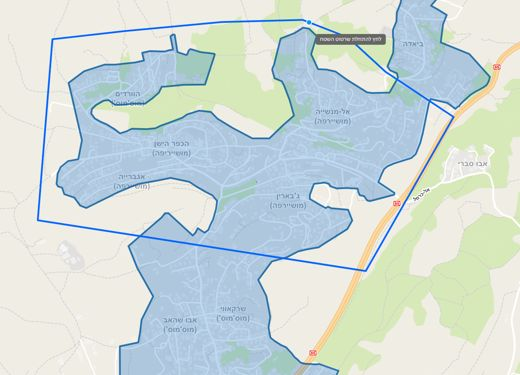
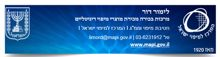
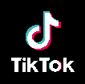
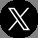
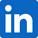
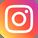
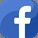
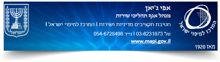
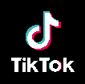
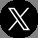
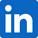
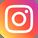
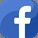

In [8]:
page = render_html(records, OUT_HTML)
print("Saved:", OUT_HTML)
import html as _h, warnings
warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
display(HTML(f'<iframe srcdoc="{_h.escape(page)}" style="width:100%;height:900px;border:1px solid #ddd;border-radius:8px"></iframe>'))

The page has a summary table of all the e-mails (date, subject, type, product, area, requester, client, recipient, attachments). Click a subject to jump to its card, which shows the requested information, the extracted fields, the attached file and all the e-mail details. At the bottom, **"ההודעות המקוריות"** shows all 5 files as they are (headers, full body, attachments), each linked to its card.